In [13]:
from google.colab import files
uploaded = files.upload()

Saving Screenshot 2026-10-27 193018.png to Screenshot 2026-10-27 193018.png


In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input, decode_predictions

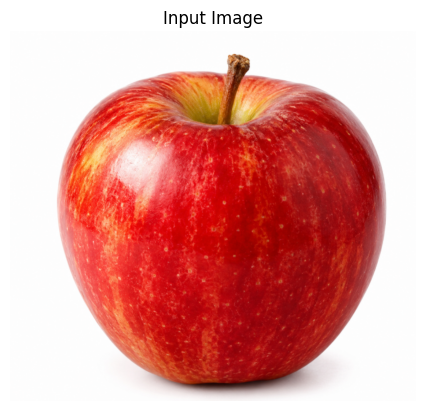

In [15]:
filename = list(uploaded.keys())[0]
image = cv2.imread(filename)

plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Input Image")
plt.axis("off")
plt.show()

In [16]:
model = MobileNetV2(weights="imagenet")

In [17]:
img = cv2.resize(image, (224, 224))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img = np.expand_dims(img, axis=0)
img = preprocess_input(img)

In [18]:
predictions = model.predict(img)
results = decode_predictions(predictions, top=5)[0]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


In [19]:
for _, label, confidence in results:
    print(label, ":", round(confidence * 100, 2), "%")

pomegranate : 27.04 %
Granny_Smith : 17.47 %
orange : 3.95 %
pitcher : 1.47 %
acorn_squash : 1.13 %


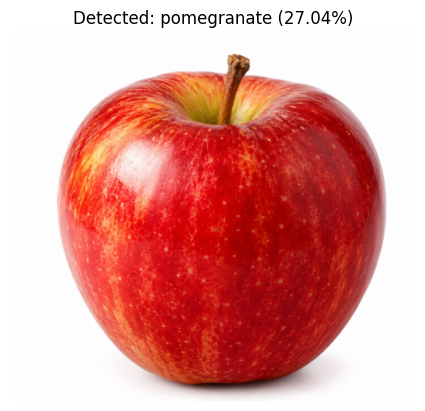

In [20]:
label = results[0][1]
score = results[0][2] * 100

plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title(f"Detected: {label} ({score:.2f}%)")
plt.axis("off")
plt.show()